# Lab: Landmark Recognition Using the SIFT Algorithm

This notebook implements the six tasks of the lab assignment:

| Task | Content | Section |
|---|---|---|
| 1 | Landmark image database (one folder per landmark) | Setup + Task 1 |
| 2 | SIFT feature extraction from grayscale reference images | Task 2 |
| 3 | Query image processing | Task 3 |
| 4 | Brute-Force matching (L2), k=2 KNN, Lowe's ratio test, ranking, threshold-based decision | Task 4 |
| 5 | RANSAC homography and landmark localization (polygon) | Task 5 |
| 6 | Performance evaluation on rotated, resized, dark, different-view and unknown queries | Task 6 |

**How to run:** `Runtime → Run all`. The first run downloads the reference images from Wikimedia Commons (about 1 minute). If that fails, upload images manually (see the note in Task 1).

In [1]:
# Colab ships OpenCV 4.x, which includes SIFT (cv2.SIFT_create).
# If the check below fails, run:  !pip install -q opencv-contrib-python-headless
import os, json, time, pickle, shutil, urllib.parse, urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
assert hasattr(cv2, "SIFT_create"), "SIFT not available - install opencv-contrib-python-headless"

OpenCV: 5.0.0


## Configuration

In [2]:
BASE        = Path(os.environ.get("LANDMARK_BASE", "/content/landmark_lab"))
DB_DIR      = BASE / "landmark_db"    # Task 1: one sub-folder per landmark (reference images)
TEST_DIR    = BASE / "test_images"    # held-out photos, never stored in the database
RESULTS_DIR = BASE / "results"        # tables, pickled descriptors, screenshots
for d in (DB_DIR, TEST_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

LANDMARK_QUERIES = {
    "Eiffel Tower":        ["Eiffel Tower Paris", "Eiffel Tower at night", "Eiffel Tower from below"],
    "Taj Mahal":           ["Taj Mahal Agra", "Taj Mahal reflecting pool", "Taj Mahal gardens"],
    "Colosseum":           ["Colosseum Rome", "Colosseum exterior", "Colosseum arches"],
    "Statue of Liberty":   ["Statue of Liberty New York", "Statue of Liberty close up", "Statue of Liberty harbor"],
    "Great Wall of China": ["Great Wall of China", "Great Wall of China mountains", "Great Wall of China watchtower"],
}
UNKNOWN_LANDMARK = "Not in database"       # folder name for the unknown-landmark test
UNKNOWN_QUERIES  = ["Pyramid of Giza"]     # a landmark that is NOT in the database

IMAGES_PER_LANDMARK_DB   = 5   # reference images per landmark
IMAGES_PER_LANDMARK_TEST = 2   # held-out images per landmark (test queries)
UNKNOWN_TEST_IMAGES      = 2

# SIFT and matching parameters (the matching threshold is a defined, fixed value)
MAX_SIDE             = 800   # longest image side in pixels after resizing
SIFT_FEATURES        = 2000  # cap on keypoints per image
LOWE_RATIO           = 0.75  # Lowe's ratio test
MIN_GOOD_MATCHES     = 12    # rule 1: reliable matches needed for a landmark
MIN_INLIERS          = 10    # rule 2: RANSAC homography inliers needed
MIN_INLIER_MARGIN    = 5     # rule 3: lead over the second-best landmark
RANSAC_REPROJ_THRESH = 5.0   # pixels

## Task 1: Build the landmark image database

Reference images are downloaded from Wikimedia Commons (free-licensed photos). Each landmark gets
several photos from different search phrases (different views and distances). Two extra photos per
landmark are kept **out of the database** as test queries. Some downloaded images may be
irrelevant, so check the thumbnails in the review cell below.

**Manual alternative:** if the download is blocked, put 5 photos per landmark into
`/content/landmark_lab/landmark_db/<Landmark Name>/` (using the file panel on the left), and 2 test
photos into `/content/landmark_lab/test_images/<Landmark Name>/`, then skip the download cell.

In [3]:
API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "LandmarkSIFTLab/1.0 (university lab project)"}

def commons_image_urls(query, limit=10):
    """JPEG/PNG image URLs returned by a Wikimedia Commons file search."""
    params = {
        "action": "query", "format": "json", "generator": "search",
        "gsrsearch": f"filetype:bitmap {query}", "gsrnamespace": 6, "gsrlimit": limit,
        "prop": "imageinfo", "iiprop": "url|mime", "iiurlwidth": MAX_SIDE,
    }
    req = urllib.request.Request(f"{API}?{urllib.parse.urlencode(params)}", headers=HEADERS)
    with urllib.request.urlopen(req, timeout=30) as r:
        data = json.load(r)
    urls = []
    for page in data.get("query", {}).get("pages", {}).values():
        info = (page.get("imageinfo") or [{}])[0]
        if info.get("mime") in ("image/jpeg", "image/png"):
            u = info.get("thumburl") or info.get("url")
            if u:
                urls.append(u)
    return urls

def fetch_images(queries, out_dir, n):
    """Download up to n distinct, readable images for the search queries."""
    out_dir.mkdir(parents=True, exist_ok=True)
    candidates = []
    for q in queries:
        try:
            candidates += commons_image_urls(q)
        except Exception as e:
            print(f"  search failed for '{q}': {e}")
        time.sleep(1)
    saved, seen = [], set()
    for u in candidates:
        if len(saved) >= n:
            break
        if u in seen:
            continue
        seen.add(u)
        ext = ".png" if u.lower().split("?")[0].endswith(".png") else ".jpg"
        dest = out_dir / f"img_{len(saved):02d}{ext}"
        try:
            req = urllib.request.Request(u, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=30) as r:
                dest.write_bytes(r.read())
            if cv2.imread(str(dest)) is None:
                dest.unlink()
                continue
            saved.append(dest)
        except Exception as e:
            print(f"  download failed: {e}")
        time.sleep(0.5)
    return saved

def build_landmark(label, queries):
    db_dir, test_dir = DB_DIR / label, TEST_DIR / label
    if db_dir.exists() and len(list(db_dir.glob("*"))) >= IMAGES_PER_LANDMARK_DB:
        print(f"{label}: already present, skipping download")
        return
    total = IMAGES_PER_LANDMARK_DB + IMAGES_PER_LANDMARK_TEST
    files = fetch_images(queries, BASE / "downloads" / label, total)
    for d in (db_dir, test_dir):
        shutil.rmtree(d, ignore_errors=True)
        d.mkdir(parents=True)
    for f in files[:IMAGES_PER_LANDMARK_DB]:
        shutil.copy(f, db_dir / f.name)
    for f in files[IMAGES_PER_LANDMARK_DB:]:
        shutil.copy(f, test_dir / f.name)
    print(f"{label}: {min(len(files), IMAGES_PER_LANDMARK_DB)} database / "
          f"{max(0, len(files) - IMAGES_PER_LANDMARK_DB)} test images")

for label, queries in LANDMARK_QUERIES.items():
    build_landmark(label, queries)

unk_dir = TEST_DIR / UNKNOWN_LANDMARK
if not unk_dir.exists() or not any(unk_dir.iterdir()):
    shutil.rmtree(unk_dir, ignore_errors=True)
    unk_dir.mkdir(parents=True)
    for f in fetch_images(UNKNOWN_QUERIES, BASE / "downloads" / "unknown", UNKNOWN_TEST_IMAGES):
        shutil.copy(f, unk_dir / f.name)
print("Unknown-landmark test images:", len(list(unk_dir.glob("*"))))

Eiffel Tower: 5 database / 2 test images
Taj Mahal: 5 database / 2 test images
Colosseum: 5 database / 2 test images
Statue of Liberty: 5 database / 2 test images
Great Wall of China: 5 database / 2 test images
Unknown-landmark test images: 2


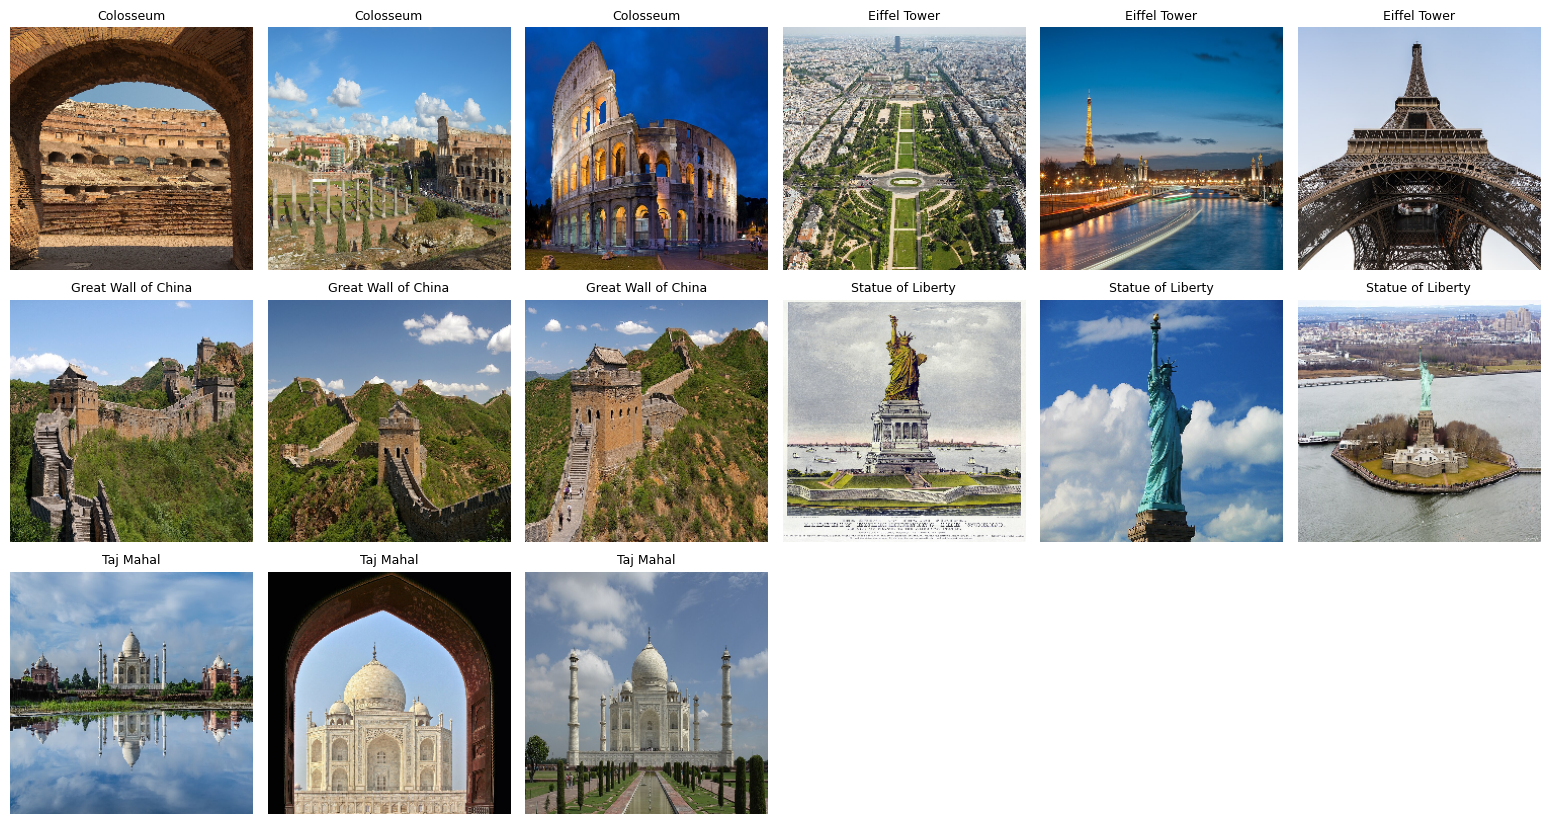

In [4]:
def show_images(images, titles=None, ncols=4, figsize_per=(3.6, 3.6)):
    """Grid display; grayscale (2-D) and BGR images are both accepted."""
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, (ax, img) in enumerate(zip(axes, images)):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if titles:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    plt.show()

# Review cell: check that the downloaded images really show each landmark.
review = []
for folder in sorted(p for p in DB_DIR.iterdir() if p.is_dir()):
    for f in sorted(folder.iterdir())[:3]:
        img = cv2.imread(str(f))
        if img is not None:
            review.append((cv2.resize(img, (240, 240)), folder.name))
if review:
    show_images([r[0] for r in review], [r[1] for r in review], ncols=6, figsize_per=(2.6, 2.8))

## Task 2: SIFT feature extraction for the reference images

Each reference image is converted to grayscale, SIFT detects keypoints and computes 128-D
descriptors. Descriptors are stored with their landmark labels in `feature_db.pkl`.

In [5]:
def to_gray(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

def resize_max(img, max_side=MAX_SIDE):
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return img

sift = cv2.SIFT_create(nfeatures=SIFT_FEATURES)
bf = cv2.BFMatcher(cv2.NORM_L2)   # Brute-force matcher, Euclidean (L2) distance

def extract_sift(img_bgr):
    """Grayscale -> SIFT keypoints and descriptors (Tasks 2 and 3)."""
    kp, des = sift.detectAndCompute(to_gray(img_bgr), None)
    return list(kp), des

def draw_keypoints(img_bgr, kp):
    gray3 = cv2.cvtColor(to_gray(img_bgr), cv2.COLOR_GRAY2BGR)
    return cv2.drawKeypoints(gray3, kp, None, color=(0, 255, 0),
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

def build_database(db_root=DB_DIR):
    db = []
    for folder in sorted(p for p in db_root.iterdir() if p.is_dir()):
        for path in sorted(folder.iterdir()):
            if path.suffix.lower() not in (".jpg", ".jpeg", ".png"):
                continue
            img = cv2.imread(str(path))
            if img is None:
                print("  unreadable, skipped:", path.name)
                continue
            img = resize_max(img)
            kp, des = extract_sift(img)
            if des is None or len(kp) < 2:
                print("  too few keypoints, skipped:", path.name)
                continue
            db.append({"label": folder.name, "path": str(path), "img": img, "kp": kp, "des": des})
    return db

def save_feature_db(db, path=RESULTS_DIR / "feature_db.pkl"):
    payload = [{"label": e["label"], "path": e["path"], "descriptors": e["des"],
                "keypoints": [(k.pt, k.size, k.angle, k.response, k.octave, k.class_id) for k in e["kp"]]}
               for e in db]
    with open(path, "wb") as f:
        pickle.dump(payload, f)
    return path

db = build_database()
assert len(db) > 0, "Database is empty - check Task 1"
save_feature_db(db)

summary = (pd.DataFrame([{"landmark": e["label"], "keypoints": len(e["kp"])} for e in db])
           .groupby("landmark")
           .agg(reference_images=("keypoints", "size"), total_descriptors=("keypoints", "sum")))
print(summary)
print(f"\nTotal reference images: {len(db)}; descriptor dimension: {db[0]['des'].shape[1]}")

                     reference_images  total_descriptors
landmark                                                
Colosseum                           5              10004
Eiffel Tower                        5               7927
Great Wall of China                 5              10003
Statue of Liberty                   5               6723
Taj Mahal                           5               8395

Total reference images: 25; descriptor dimension: 128


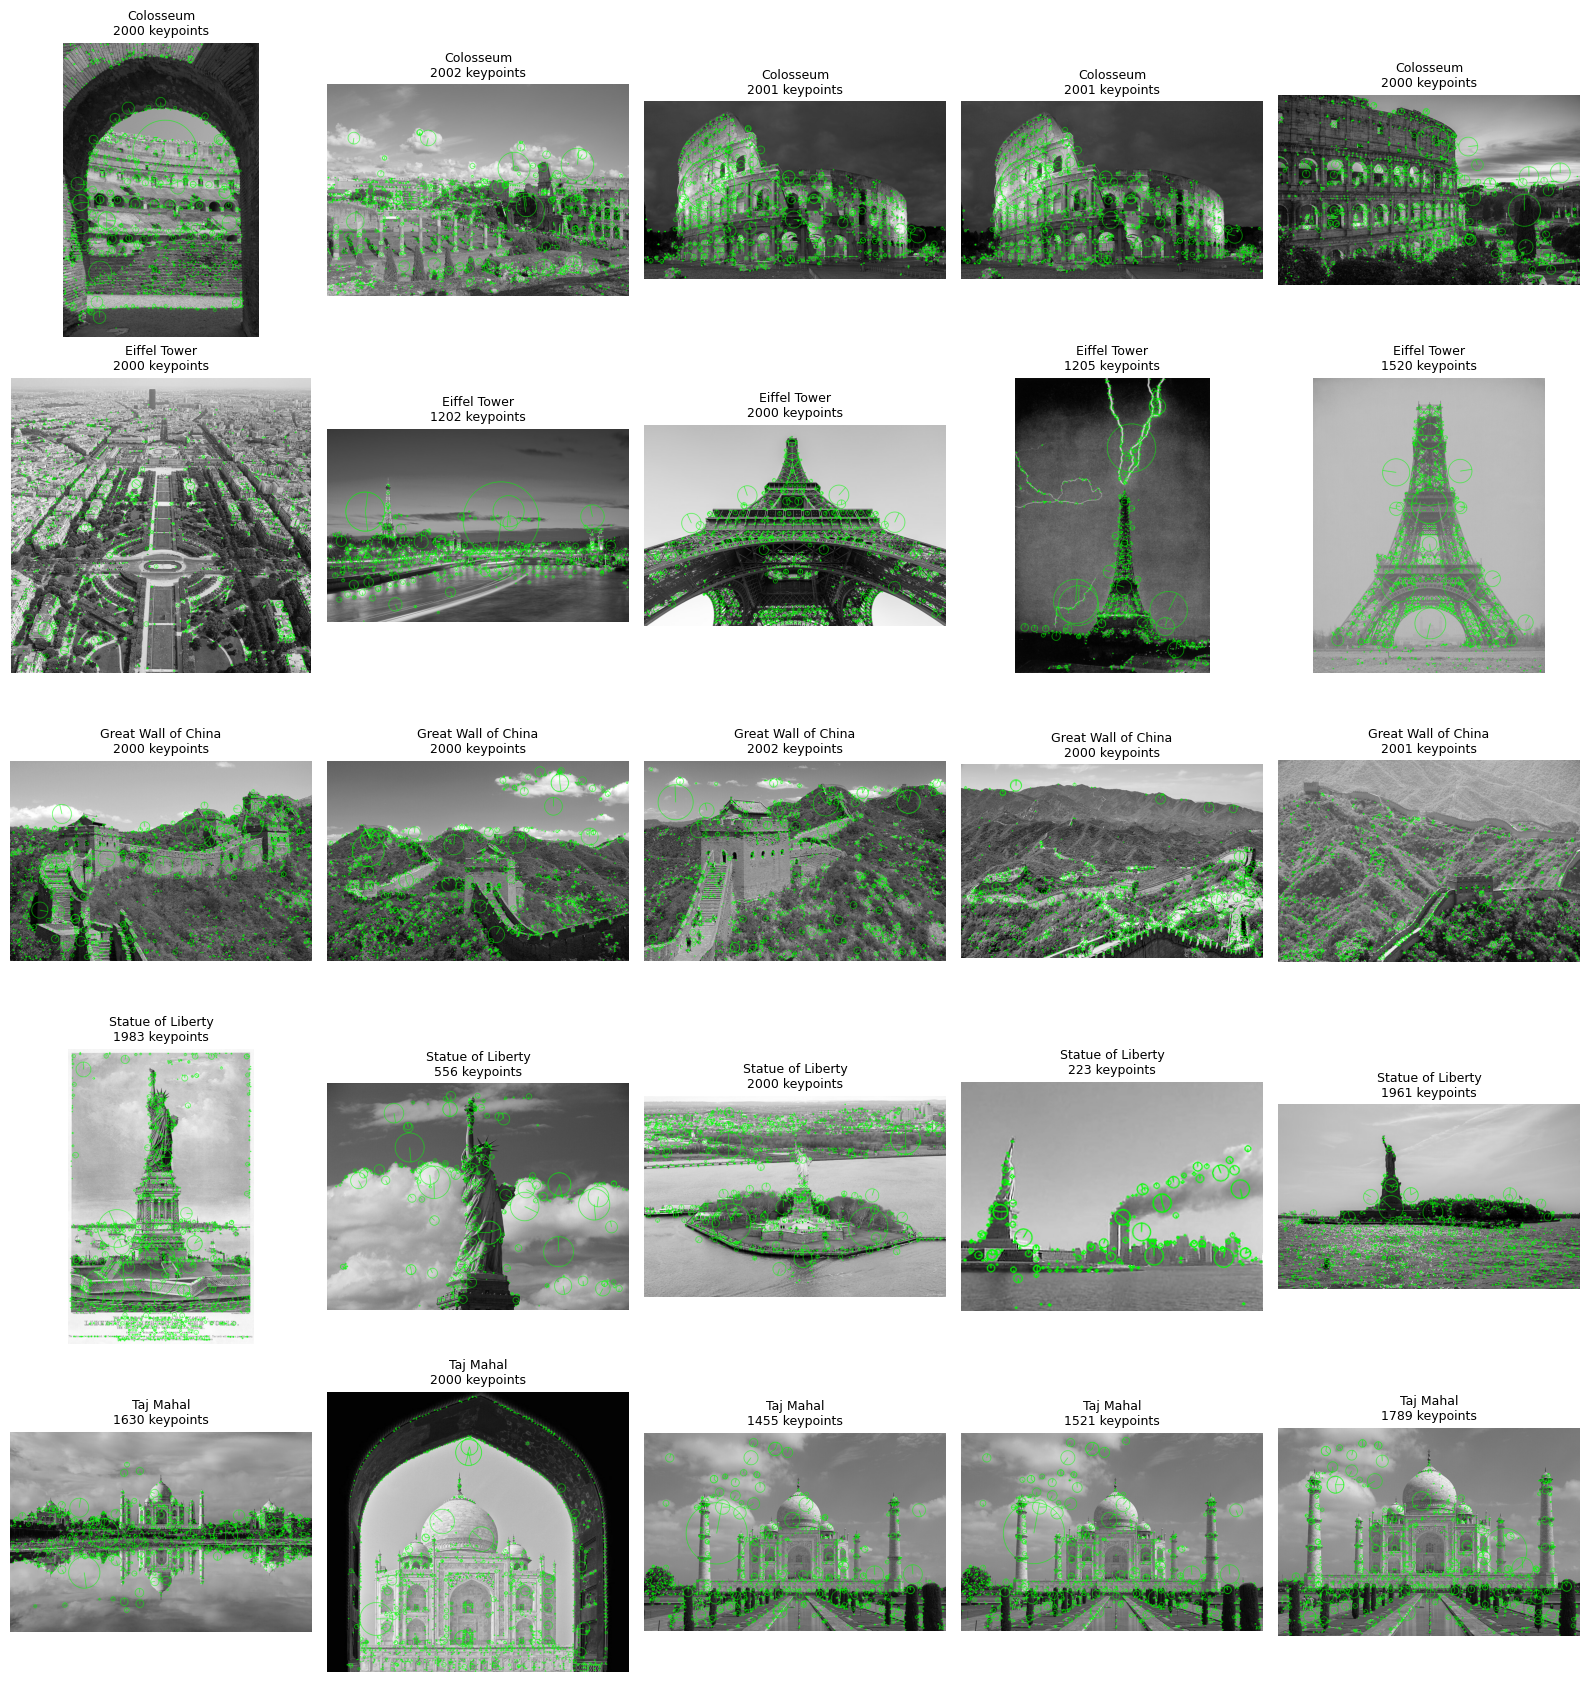

In [6]:
# Task 2, step 4: reference images with detected SIFT keypoints
show_images([draw_keypoints(e["img"], e["kp"]) for e in db],
            [f'{e["label"]}\n{len(e["kp"])} keypoints' for e in db],
            ncols=5, figsize_per=(3.2, 3.4))

## Task 3: Query image processing

The query is converted to grayscale, SIFT keypoints and descriptors are extracted, and the query
is displayed with its keypoints.

In [7]:
def process_query(img_bgr):
    img = resize_max(img_bgr)
    kp, des = extract_sift(img)
    print(f"Query: {img.shape[1]} x {img.shape[0]} px | keypoints: {len(kp)} | "
          f"descriptors: {None if des is None else des.shape}")
    show_images([draw_keypoints(img, kp)], [f"Query image - {len(kp)} SIFT keypoints"],
                ncols=1, figsize_per=(7, 6))
    return img, kp, des

## Task 4: Feature matching and landmark recognition

* Brute-force matcher with Euclidean distance, `knnMatch(k=2)`.
* Lowe's ratio test removes ambiguous matches; the survivors are the **reliable matches**.
* Each landmark is scored by its best reference image. Landmarks are ranked by RANSAC inliers.
* **The top candidate is not accepted just because it has the most matches.** It must also:
  1. have at least `MIN_GOOD_MATCHES` reliable matches,
  2. have at least `MIN_INLIERS` geometrically consistent (RANSAC) matches, and
  3. lead the second-best landmark by at least `MIN_INLIER_MARGIN` inliers.
  Otherwise the image is rejected as an unknown landmark.

In [8]:
def lowe_matches(des_q, des_r):
    """KNN (k=2) matching followed by Lowe's ratio test."""
    if des_q is None or des_r is None or len(des_r) < 2:
        return []
    good = []
    for pair in bf.knnMatch(des_q, des_r, k=2):
        if len(pair) == 2 and pair[0].distance < LOWE_RATIO * pair[1].distance:
            good.append(pair[0])
    return good

def verify_homography(kp_q, kp_r, good):
    """RANSAC homography from reference to query. Returns (H, inlier mask, inlier count)."""
    if len(good) < 4:
        return None, None, 0
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_REPROJ_THRESH)
    if H is None:
        return None, None, 0
    mask = mask.ravel().astype(bool)
    return H, mask, int(mask.sum())

def match_against_database(kp_q, des_q, db):
    records = []
    for ref in db:
        good = lowe_matches(des_q, ref["des"])
        rec = {"label": ref["label"], "ref": ref, "good": len(good), "good_list": good,
               "H": None, "mask": None, "inliers": 0}
        if len(good) >= MIN_GOOD_MATCHES:          # only verify plausible candidates
            rec["H"], rec["mask"], rec["inliers"] = verify_homography(kp_q, ref["kp"], good)
        records.append(rec)
    return records

def rank_landmarks(records):
    """Best reference image per landmark, then landmarks ranked by RANSAC inliers, then matches."""
    best = {}
    for r in records:
        b = best.get(r["label"])
        if b is None or (r["inliers"], r["good"]) > (b["inliers"], b["good"]):
            best[r["label"]] = r
    for lm, rec in best.items():
        rec["landmark_good"] = max(r["good"] for r in records if r["label"] == lm)
    return sorted(best.values(), key=lambda r: (r["inliers"], r["good"]), reverse=True)

def decide(ranking):
    top = ranking[0]
    runner_up = ranking[1]["inliers"] if len(ranking) > 1 else 0
    reasons = []
    if top["landmark_good"] < MIN_GOOD_MATCHES:
        reasons.append(f"only {top['landmark_good']} reliable matches (< {MIN_GOOD_MATCHES})")
    if top["inliers"] < MIN_INLIERS:
        reasons.append(f"only {top['inliers']} RANSAC inliers (< {MIN_INLIERS})")
    if top["inliers"] - runner_up < MIN_INLIER_MARGIN:
        reasons.append(f"too close to 2nd candidate ({top['inliers']} vs {runner_up} inliers)")
    return len(reasons) == 0, reasons

def ranking_table(ranking):
    return pd.DataFrame([{"Rank": i + 1, "Landmark": r["label"],
                          "Reliable matches": r["landmark_good"], "RANSAC inliers": r["inliers"]}
                         for i, r in enumerate(ranking)])

## Task 5: Landmark localization

For an accepted match, the four corners of the best reference image are projected into the query
with the RANSAC homography and drawn as a polygon. The polygon is drawn only when the geometry is
plausible: finite, not too small, convex, not flipped, and with its centre inside the query image.
Otherwise a message is shown instead.

In [9]:
def signed_area(pts):
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)

def localize(H, ref_img, query_shape):
    h, w = ref_img.shape[:2]
    ref_corners = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    pts = cv2.perspectiveTransform(ref_corners.reshape(-1, 1, 2), H).reshape(-1, 2)
    if not np.all(np.isfinite(pts)):
        return None, "Localization rejected: homography is not finite."
    qh, qw = query_shape[:2]
    poly = pts.astype(np.float32)
    if abs(cv2.contourArea(poly)) < 0.01 * qh * qw:
        return None, "Localization rejected: projected region is too small."
    if not cv2.isContourConvex(poly):
        return None, "Localization rejected: projected region is not convex (unreliable geometry)."
    if np.sign(signed_area(pts)) != np.sign(signed_area(ref_corners)):
        return None, "Localization rejected: transformation flips the reference image."
    cx, cy = pts.mean(axis=0)
    if not (0 <= cx < qw and 0 <= cy < qh):
        return None, "Localization rejected: landmark centre lies outside the query image."
    return pts, "Landmark localized."

def recognize(query_bgr, db):
    """Full pipeline: Tasks 3, 4 and 5 for one query image."""
    t0 = time.perf_counter()
    q = resize_max(query_bgr)
    kp_q, des_q = extract_sift(q)
    if des_q is None or len(kp_q) == 0:
        return {"query": q, "kp_q": kp_q, "num_keypoints": 0, "ranking": [], "top": None,
                "accepted": False, "predicted": "Unknown", "closest": None,
                "reasons": ["no keypoints detected"], "pts": None,
                "loc_msg": "No localization: no keypoints.", "time_s": time.perf_counter() - t0}
    records = match_against_database(kp_q, des_q, db)
    ranking = rank_landmarks(records)
    accepted, reasons = decide(ranking)
    top = ranking[0]
    if accepted:
        pts, loc_msg = localize(top["H"], top["ref"]["img"], q.shape)
    else:
        pts, loc_msg = None, "Not recognised: no localization is attempted."
    return {"query": q, "kp_q": kp_q, "num_keypoints": len(kp_q), "ranking": ranking, "top": top,
            "accepted": accepted, "predicted": top["label"] if accepted else "Unknown",
            "closest": top["label"], "reasons": reasons, "pts": pts, "loc_msg": loc_msg,
            "time_s": time.perf_counter() - t0}

def print_verdict(res):
    if res["top"] is None:
        print("No keypoints - cannot classify.")
        return
    if res["accepted"]:
        print(f"RECOGNIZED: {res['predicted']}")
    else:
        print(f"REJECTED: unknown landmark (closest candidate: {res['closest']})")
        print("  reasons: " + "; ".join(res["reasons"]))
    print(f"Keypoints: {res['num_keypoints']} | Reliable matches: {res['top']['landmark_good']} | "
          f"RANSAC inliers: {res['top']['inliers']} | Time: {res['time_s']:.3f} s")
    print(res["loc_msg"])

def show_matches(res):
    top = res["top"]
    inliers = [m for m, keep in zip(top["good_list"], top["mask"]) if keep] if top["mask"] is not None else []
    vis = cv2.drawMatches(res["query"], res["kp_q"], top["ref"]["img"], top["ref"]["kp"], inliers, None,
                          matchColor=(0, 255, 0), singlePointColor=(0, 0, 255),
                          flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(14, 6))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"RANSAC-inlier matches: query <-> best reference of '{top['label']}' ({len(inliers)} matches)")
    plt.show()

def show_localization(res):
    img = cv2.cvtColor(res["query"], cv2.COLOR_BGR2RGB).copy()
    if res["accepted"] and res["pts"] is not None:
        cv2.polylines(img, [res["pts"].astype(np.int32)], True, (255, 0, 0), 4)  # red in RGB
    top = res["top"]
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.imshow(img)
    ax.axis("off")
    status = "RECOGNIZED" if res["accepted"] else "REJECTED"
    ax.set_title(f"{status}: {res['predicted']}", fontsize=14,
                 color="green" if res["accepted"] else "red")
    info = (f"Predicted landmark : {res['predicted']}\n"
            f"Reliable matches   : {top['landmark_good']}\n"
            f"RANSAC inliers     : {top['inliers']}\n"
            f"Keypoints (query)  : {res['num_keypoints']}\n"
            f"Processing time    : {res['time_s']:.3f} s\n"
            f"{res['loc_msg']}")
    ax.text(0.02, 0.02, info, transform=ax.transAxes, va="bottom", fontsize=9, family="monospace",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    plt.tight_layout()
    plt.show()

def run_query(img_path_or_array, name="query"):
    img = cv2.imread(str(img_path_or_array)) if isinstance(img_path_or_array, (str, Path)) else img_path_or_array
    print("--- Task 3: query processing ---")
    process_query(img)
    res = recognize(img, db)
    print("\n--- Task 4: matching and ranking ---")
    print(ranking_table(res["ranking"]).to_string(index=False) if res["ranking"] else "no candidates")
    print("\n--- Decision ---")
    print_verdict(res)
    if res["top"] is not None:
        show_matches(res)
        show_localization(res)
    return res

## Demo: run the complete pipeline on one query

The demo uses a held-out photo (not in the database). To classify your own photo, use the upload cell
after this one.

--- Task 3: query processing ---
Query: 800 x 645 px | keypoints: 2000 | descriptors: (2000, 128)


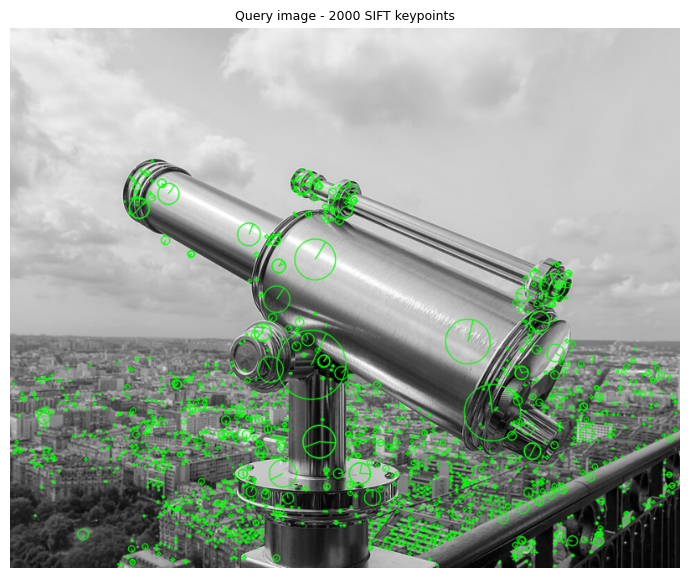


--- Task 4: matching and ranking ---
 Rank            Landmark  Reliable matches  RANSAC inliers
    1           Taj Mahal                13               6
    2        Eiffel Tower                12               5
    3 Great Wall of China                13               5
    4   Statue of Liberty                18               4
    5           Colosseum                12               4

--- Decision ---
REJECTED: unknown landmark (closest candidate: Taj Mahal)
  reasons: only 6 RANSAC inliers (< 10); too close to 2nd candidate (6 vs 5 inliers)
Keypoints: 2000 | Reliable matches: 13 | RANSAC inliers: 6 | Time: 2.832 s
Not recognised: no localization is attempted.


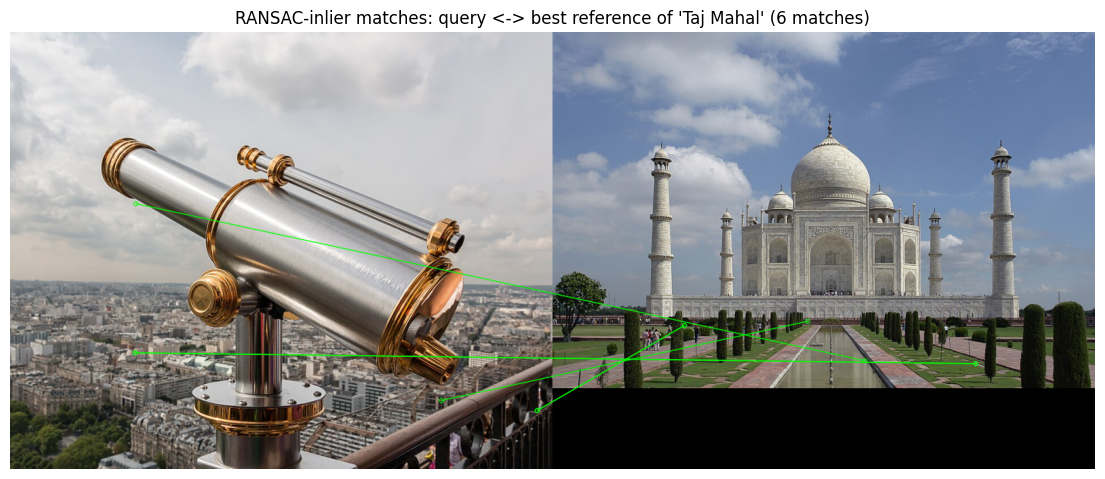

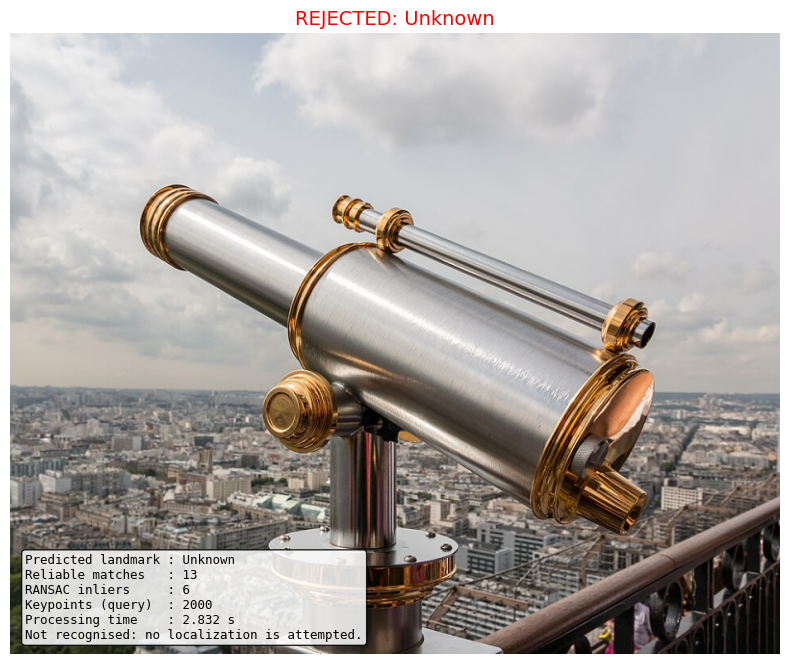

In [10]:
demo_dir = TEST_DIR / "Eiffel Tower"
demo_path = sorted(demo_dir.glob("*"))[0] if demo_dir.exists() and any(demo_dir.iterdir()) else None
if demo_path is not None:
    demo_res = run_query(demo_path, name="demo")
else:
    print("No held-out Eiffel Tower photo found - run the download cell or use the upload cell.")

Saving WhatsApp Image 2026-10-15 at 10.13.09 AM.jpeg to WhatsApp Image 2026-10-15 at 10.13.09 AM.jpeg

======== WhatsApp Image 2026-10-15 at 10.13.09 AM.jpeg ========
--- Task 3: query processing ---
Query: 600 x 800 px | keypoints: 1074 | descriptors: (1074, 128)


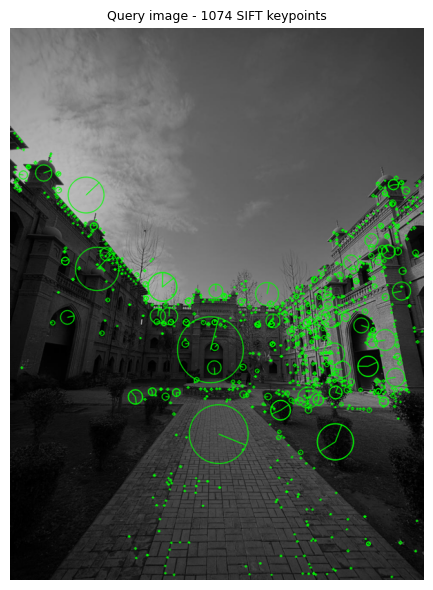


--- Task 4: matching and ranking ---
 Rank            Landmark  Reliable matches  RANSAC inliers
    1   Statue of Liberty                33               8
    2           Taj Mahal                26               6
    3           Colosseum                37               6
    4 Great Wall of China                25               6
    5        Eiffel Tower                19               5

--- Decision ---
REJECTED: unknown landmark (closest candidate: Statue of Liberty)
  reasons: only 8 RANSAC inliers (< 10); too close to 2nd candidate (8 vs 6 inliers)
Keypoints: 1074 | Reliable matches: 33 | RANSAC inliers: 8 | Time: 2.092 s
Not recognised: no localization is attempted.


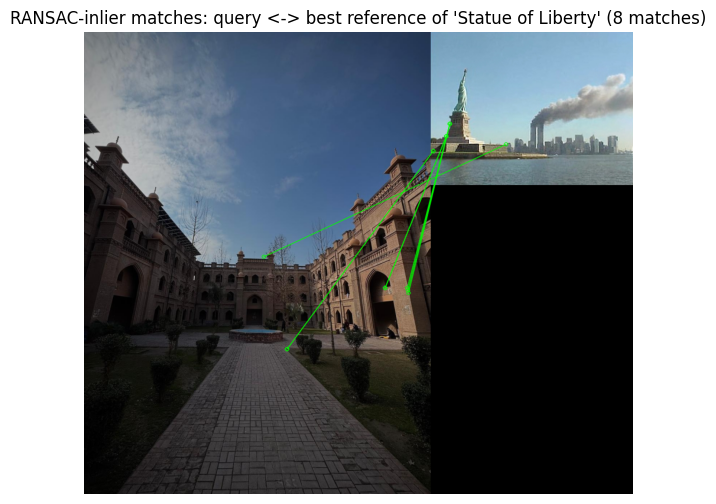

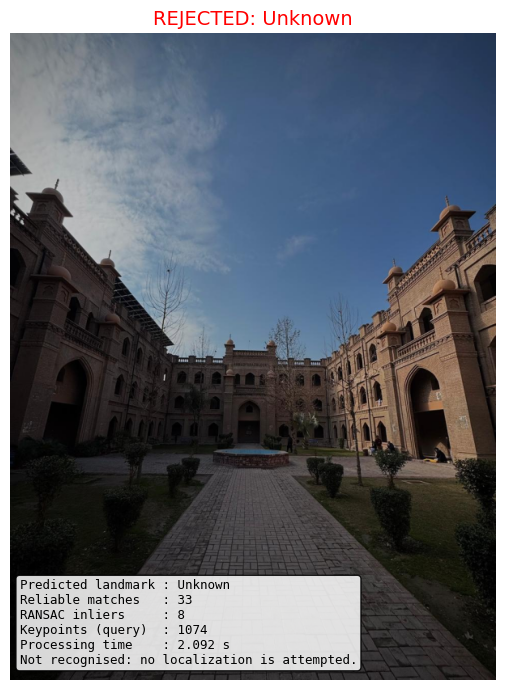

In [11]:
 classify your own photo.
try:
    from google.colab import files
    uploaded = files.upload()
    for fname, data in uploaded.items():
        p = BASE / "query_images" / fname
        p.parent.mkdir(parents=True, exist_ok=True)
        p.write_bytes(data)
        print("\n========", fname, "========")
        run_query(p, name=Path(fname).stem)
except ImportError:
    print("Not running in Colab: put your image in", BASE / "query_images", "and call run_query(path).")

## Task 6: Performance evaluation

Test queries for each landmark (held-out photos, not in the database):

* **Original** - a held-out photo.
* **Rotated 45°** - the original rotated, with the canvas enlarged so nothing is cut off.
* **Resized 50%** - the original at half resolution.
* **Reduced brightness** - the original multiplied by 0.4.
* **Different viewpoint** - a second held-out photo of the same landmark.

Unknown-landmark test: photos of a landmark that is not in the database (should be **rejected**).

For each test the table records the predicted landmark, keypoints, reliable matches, RANSAC inliers,
decision, correctness and processing time.

In [12]:
def rotate_image(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    new_w, new_h = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += new_w / 2 - w / 2
    M[1, 2] += new_h / 2 - h / 2
    return cv2.warpAffine(img, M, (new_w, new_h), borderValue=(0, 0, 0))

def build_test_cases():
    cases = []   # (ground-truth label, condition, image)
    for label in LANDMARK_QUERIES:
        paths = sorted((TEST_DIR / label).glob("*")) if (TEST_DIR / label).exists() else []
        if len(paths) < 2:
            print(f"Skipping {label}: needs 2 held-out test images")
            continue
        base = resize_max(cv2.imread(str(paths[0])))
        cases += [
            (label, "Original", base),
            (label, "Rotated 45 deg", rotate_image(base, 45)),
            (label, "Resized 50%", cv2.resize(base, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)),
            (label, "Reduced brightness", cv2.convertScaleAbs(base, alpha=0.4, beta=0)),
            (label, "Different viewpoint", resize_max(cv2.imread(str(paths[1])))),
        ]
    unk = TEST_DIR / UNKNOWN_LANDMARK
    for p in sorted(unk.glob("*")) if unk.exists() else []:
        cases.append((UNKNOWN_LANDMARK, "Landmark not in database", resize_max(cv2.imread(str(p)))))
    return cases

rows = []
for true_label, condition, img in build_test_cases():
    res = recognize(img, db)
    if true_label == UNKNOWN_LANDMARK:
        correct = not res["accepted"]                      # must be rejected
    else:
        correct = res["accepted"] and res["predicted"] == true_label
    top = res["top"]
    rows.append({
        "Ground truth": true_label,
        "Condition": condition,
        "Predicted": res["predicted"],
        "Closest candidate": res["closest"] or "-",
        "Keypoints": res["num_keypoints"],
        "Reliable matches": top["landmark_good"] if top else 0,
        "RANSAC inliers": top["inliers"] if top else 0,
        "Decision": "Recognized" if res["accepted"] else "Rejected",
        "Correct": bool(correct),
        "Time (s)": round(res["time_s"], 3),
    })

results = pd.DataFrame(rows)
results.to_csv(RESULTS_DIR / "test_results.csv", index=False)
print(results.to_string(index=False))

       Ground truth                Condition           Predicted   Closest candidate  Keypoints  Reliable matches  RANSAC inliers   Decision  Correct  Time (s)
       Eiffel Tower                 Original             Unknown           Taj Mahal       2000                13               6   Rejected    False     4.225
       Eiffel Tower           Rotated 45 deg             Unknown           Taj Mahal       2001                16               6   Rejected    False     2.942
       Eiffel Tower              Resized 50%             Unknown   Statue of Liberty        917                 9               0   Rejected    False     1.205
       Eiffel Tower       Reduced brightness             Unknown Great Wall of China       1432                12               5   Rejected    False     1.992
       Eiffel Tower      Different viewpoint             Unknown   Statue of Liberty       2000                 8               0   Rejected    False     2.675
          Taj Mahal                 Orig

In [13]:
known = results[results["Ground truth"] != UNKNOWN_LANDMARK]
unknown = results[results["Ground truth"] == UNKNOWN_LANDMARK]

print("Accuracy by condition (%):")
print((results.groupby("Condition", sort=False)["Correct"].mean() * 100).round(1).to_string())
print(f"\nKnown-landmark queries correct: {known['Correct'].sum()} / {len(known)}")
print(f"Wrong landmark predicted (false accepts of a known landmark): "
      f"{int((known['Decision'] == 'Recognized').sum() - known['Correct'].sum())}")
print(f"Unknown-landmark queries correctly rejected: {int(unknown['Correct'].sum())} / {len(unknown)}")
print(f"Mean processing time: {results['Time (s)'].mean():.3f} s per query")

Accuracy by condition (%):
Condition
Original                     60.0
Rotated 45 deg               60.0
Resized 50%                  60.0
Reduced brightness           60.0
Different viewpoint          20.0
Landmark not in database    100.0

Known-landmark queries correct: 13 / 25
Wrong landmark predicted (false accepts of a known landmark): 0
Unknown-landmark queries correctly rejected: 2 / 2
Mean processing time: 2.375 s per query


## Discussion

**Expected behaviour (what the method is designed to do):**

* **Scale and rotation:** SIFT descriptors are invariant to scale and in-plane rotation, so the
  rotated and resized queries should still match many keypoints.
* **Illumination:** descriptors are normalised, so a moderate brightness reduction should keep
  most matches. Very dark or blown-out images lose keypoints.
* **Viewpoint:** a landmark is a 3-D object, but the RANSAC homography assumes a planar scene.
  Matches should survive moderate viewpoint change. Large changes break the homography, and the
  geometry check rejects the polygon rather than drawing a wrong one.
* **Unknown landmarks:** a photo of a landmark not in the database should produce few reliable matches
  and few inliers, so the threshold rules should reject it. The decision never relies on the
  largest raw match count alone.

**Results and limitations:** complete this section after running the notebook, using the table and
accuracy figures above. Discuss each failed case: which condition failed, and whether the reason was
low keypoint count, too few reliable matches, a homography that failed the geometry check, or the
margin rule. Also comment on:

* the effect of the thresholds (`MIN_GOOD_MATCHES`, `MIN_INLIERS`, `MIN_INLIER_MARGIN`);
* the processing time and how it scales with database size (one matcher call per reference image);
* the dependence on the quality of downloaded images, and on how many photos there are per landmark.